#Our Research Questions:

**Do FanGraphs' evaluations systematically misvalue players based on demographic factors like age and developmental origins (highschool, college, or international signing), and to what extent do algorithmic "Risk" penalties reflect these differences? How is a player's signing bonus related to their developmental origin and what impact does that have on their evaluation?**

Variables of interest: Average WAR, FV, Risk, Signing Bonus, Background, Ranking, Age


**Do FanGraphs' evaluations exhibit systemic bias toward certain physical archetypes (e.g., height, weight), and do players who fall outside these traditional molds systematically outperform their projections?**

Variables of Interest: Average WAR, FV, Height, Weight, Position      


**Do FanGraphs' evaluations overvalue raw, measurable tools (e.g., fastball velocity, max exit velocity) at the expense of functional game skills (e.g., command, bat control, hit tool)?**

Variables of Interest: Average WAR, FEV
*   Metrics: Exit Velocity, Fastball Velocity, Breaking Ball Spin, Hard Hit %
*   Hitter Grades: Hit, PWR, SPD, FLD
*   Pitcher Grades: FB, CB, CH, SL, CMD


In [144]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [145]:
#Loads in data
data=pd.read_csv("Prospect Rankings Data (Uncleaned).csv")

#**Data Cleaning**

Prospects Latest Rankings

In [146]:
#Sorts by year, then groups by Name and takes the last entry
clean_data=data.sort_values("Year").groupby("Name", as_index=False).last()

Add Average War Per Year Played Column (Used to determine players total production)

In [181]:
#Columns with WAR in Name
war_cols = [col for col in clean_data.columns if 'WAR' in col.upper()]
#Fill all NA values with 0
clean_data[war_cols] = clean_data[war_cols].fillna(0)
#Adds Column Total WAR
clean_data["Total WAR"] = clean_data[war_cols].sum(axis=1)
#Identifies seasons where player played
non_zero_seasons = (clean_data[war_cols] != 0).sum(axis=1)
#Adds Average WAR column finding average of seasons player recorded a non-zero WAR
clean_data["Average WAR"] = np.where(non_zero_seasons > 0,
    clean_data["Total WAR"] / non_zero_seasons,0)
#Adds Seasons Played Column
clean_data["Seasons Played"] = non_zero_seasons
clean_data.sort_values("Average WAR", ascending=False).head(5)

,Name,Year,Rank,Org.Rk,Org,Pos,Current.Level,FV,ETA,Risk,...,2026 WAR,Total WAR,Average WAR,Seasons Played,Background,Pos_Group,had_tj,Height Build,Weight Build,Wt_Bin
258,Bobby Witt Jr.,2022,2,1.0,KCR,SS,MLB,65.0,2022,Med,...,6.9566,73.97522,10.567889,7,High School,Middle IF,<NA>,Typical,Heavy,200.0
1351,Julio Rodríguez,2022,3,1.0,SEA,CF,MLB,65.0,2022,High,...,2.5820,52.32062,7.474374,7,International,OF,<NA>,Typical,Heavy,220.0
760,Elly De La Cruz,2023,4,1.0,CIN,SS,MLB,60.0,2024,High,...,6.4490,44.39115,7.398525,6,International,Middle IF,<NA>,Tall,Heavy,200.0
1874,Pete Crow-Armstrong,2023,31,1.0,CHC,CF,MLB,55.0,2024,Med,...,10.6195,41.52240,6.920400,6,High School,OF,<NA>,Typical,Typical,180.0
547,Corbin Carroll,2023,2,1.0,ARI,LF,MLB,65.0,2023,Med,...,4.2278,48.29242,6.898917,7,High School,OF,<NA>,Short,Light,160.0


Background Column

In [148]:
#Makes NA values in Signed From and Sign Market
signed_from = clean_data["Signed.From"].fillna("Unknown")
sign_mkt = clean_data["Sign.Mkt"].fillna("Unknown")
#Checks if prospect is signed from highschool
is_hs = signed_from.str.contains("HS|High School|Prep|Academy", case=False)
#Checks if prospect is signed from J2 market or International market or where they were signed out of is one of the common countries
is_intl = sign_mkt.isin(["J2", "Intl15"]) | signed_from.isin([
    "Dominican Republic", "Venezuela", "Cuba", "Mexico",
    "Panama", "Colombia", "Bahamas", "Canada", "Japan", "South Korea"])
is_unknown = signed_from == "Unknown"
#Makes Baground Column
clean_data["Background"] = np.select(
    condlist=[is_unknown, is_hs, is_intl],
    choicelist=["Unknown", "High School", "International"],
    default="College"
)

Drop Columns That are fully NA

In [149]:
clean_data = clean_data.dropna(axis=1, how='all')

Make FV Column Fully Numeric

In [150]:
clean_data["FV"] = clean_data["FV"].astype(str).str.replace("+", "").astype(float)

Make Bonus Column Fully Numeric

In [151]:
def clean_bonus(value):
    #If NA leave as NA
    if pd.isna(value):
        return pd.NA
    #Remove . and $
    value = str(value).strip().replace("$", "").replace(",", "").upper()
    #Mult by 1000 if ends in K and 1000000 if ends in M
    if value.endswith("K"):
        return float(value[:-1]) * 1000
    elif value.endswith("M"):
        return float(value[:-1]) * 1000000
    return value
clean_data["Bonus"] = clean_data["Bonus"].apply(clean_bonus)
#Makes sure everything is Numeric or NA
clean_data["Bonus"] = pd.to_numeric(clean_data["Bonus"], errors="coerce")

Make Height column Numeric

In [152]:
def height_to_inches(height):
    #If NA keeps NA
    if pd.isna(height):
        return pd.NA
    #Splits feet and inches
    parts = str(height).split("'")
    feet = int(parts[0].strip())
    inches = int(parts[1].replace('"', '').strip())
    #Returns height in inches
    return feet * 12 + inches
clean_data["Ht"] = clean_data["Ht"].apply(height_to_inches)

Clean grades so they are numbers (Take the second grade of the slash because that is predicted grade)

In [153]:
#Column with Grades in the form of current tool/projected tool (ex. 40/50)
grade_columns = ["FB", "SL", "CB", "CH", "CMD", "Hit", "Game.Pwr", "Raw.Pwr", "Spd", "Fld", "Arm"]
#Keeps the projected tool grade
for col in grade_columns:
    clean_data[col] = pd.to_numeric(clean_data[col].astype("string").str.split("/").str[-1], errors="coerce")

Rename Top.100 column to Rank

In [154]:
clean_data = clean_data.rename(columns={"Top.100": "Rank"})

Add Positon Group Column

In [155]:
#Unique Positions
clean_data["Pos"].unique()

array(['SIRP', 'CF', 'SP', 'MIRP', '2B', 'LHP', '1B', '3B', 'RF', 'SS',
       'C', 'RHP', 'LF', 'DH', 'OF', '3B/SIRP', 'SS/RHP', 'CF/SP',
       '1B/LHP', 'UTIL', 'SP/OF'], dtype=object)

In [156]:
position_mapping = {
    # Pitchers
    'SIRP': 'P', 'SP': 'P', 'MIRP': 'P', 'LHP': 'P', 'RHP': 'P',
    # Outfielders
    'CF': 'OF', 'RF': 'OF', 'LF': 'OF', 'OF': 'OF',
    # Corner Infielders
    '1B': 'Corner IF', '3B': 'Corner IF',
    # Middle Infielders
    '2B': 'Middle IF', 'SS': 'Middle IF',
    # Catchers and DH
    'C': 'C',
    'DH': 'DH',
    # Utility and Two-Way Players
    'UTIL': 'UTIL',
    '3B/SIRP': 'UTIL',
    'SS/RHP': 'UTIL',
    'CF/SP': 'UTIL',
    '1B/LHP': 'UTIL',
    'SP/OF': 'UTIL'
}
#Create column using .map
clean_data['Pos_Group'] = clean_data['Pos'].map(position_mapping)

Add Had TJ Column

In [157]:
conditions = [
    #Only Look at Pitchers who either did or didn't have TJ
    (clean_data["Pos_Group"] == "P") & (clean_data["TJ.Date"].notna()),
    (clean_data["Pos_Group"] == "P") & (clean_data["TJ.Date"].isna())
]
choices = [1, 0]
#Use np.select to assign 1 to pitcher who had TJ, 0 to pichers who didn't, and NA to everyone else
clean_data["had_tj"] = np.select(conditions, choices, default=pd.NA)
#Makes sure values are numeric
clean_data["had_tj"] = pd.to_numeric(clean_data["had_tj"], errors="coerce").astype("Int64")

Create Height Build and Weight Build Columns

In [158]:
#Calculate position-specific mean and standard deviation for Height
pos_mean_h = clean_data.groupby("Pos_Group")["Ht"].transform("mean")
pos_std_h = clean_data.groupby("Pos_Group")["Ht"].transform("std")

#Define conditions and corresponding labels for Height Build
conditions_height = [
    clean_data["Ht"] < (pos_mean_h - pos_std_h),
    clean_data["Ht"] > (pos_mean_h + pos_std_h)
]
choices_height = ["Short", "Tall"]

#Apply to Height Build column, defaulting to Typical
clean_data["Height Build"] = np.select(conditions_height, choices_height, default="Typical")

#Calculate position-specific mean and standard deviation for Weight
pos_mean_w = clean_data.groupby("Pos_Group")["Wt"].transform("mean")
pos_std_w = clean_data.groupby("Pos_Group")["Wt"].transform("std")

#Define conditions and corresponding labels for Weight Build
conditions_weight = [
    clean_data["Wt"] < (pos_mean_w - pos_std_w),
    clean_data["Wt"] > (pos_mean_w + pos_std_w)
]
choices_weight = ["Light", "Heavy"]

#Apply to Weight Build column, defaulting to Typical
clean_data["Weight Build"] = np.select(conditions_weight, choices_weight, default="Typical")

Final Cleaned Dataset (All Columns being used in Analysis)

In [184]:
final_data = clean_data[[
    "Name", "Year", "Org", "Rank", "Pos", "Pos_Group", "Age",
    "Ht", "Wt", "Height Build", "Weight Build",
    "Signed.From", "Sign.Mkt", "Background", "Bonus", "Risk", "FV",
    "Hit", "Game.Pwr", "Raw.Pwr", "Spd", "Pitch.Sel", "Bat.Ctrl", "Fld",
    "FB", "SL", "CB", "CH", "CMD",
    "Max.EV", "Hard.Hit.", "Tops", "RPM.Break",
    "TJ.Date", "had_tj",
    "2020 WAR", "2021 WAR", "2022 WAR", "2023 WAR", "2024 WAR", "2025 WAR", "2026 WAR",
    "Total WAR", "Seasons Played", "Average WAR"
]]


In [194]:
final_data.to_csv("Final Prospect Rankings Data.csv", index=False)

#**Summary Statistics**


In [193]:
#Transposed to fit all columns
final_data.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
Year,2450.0,2022.11,1.01,2020.0,2021.0,2022.0,2023.0,2023.0
Rank,2450.0,663.8,354.76,1.0,368.25,699.0,971.75,1255.0
Age,2450.0,23.23,2.53,17.1,21.5,23.4,25.0,33.4
Ht,2450.0,73.63,2.41,65.0,72.0,74.0,75.0,83.0
Wt,2450.0,197.26,22.4,135.0,180.0,195.0,215.0,265.0
Bonus,1788.0,1123931.77,1514789.0,0.0,170000.0,581000.0,1500000.0,25000000.0
FV,2450.0,39.84,5.47,35.0,35.0,40.0,40.0,80.0
Hit,1172.0,46.29,9.37,20.0,40.0,45.0,55.0,80.0
Game.Pwr,1172.0,45.93,9.07,20.0,40.0,45.0,50.0,80.0
Raw.Pwr,1172.0,52.73,9.7,20.0,45.0,55.0,60.0,80.0


#**Plots For Reseach Question 1**

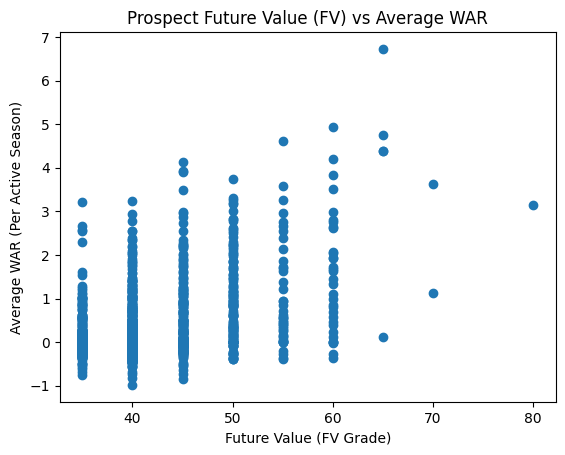

In [161]:
plt.scatter(clean_data["FV"], clean_data["Average WAR"])
plt.title("Prospect Future Value (FV) vs Average WAR")
plt.xlabel("Future Value (FV Grade)")
plt.ylabel('Average WAR (Per Active Season)')
plt.show()

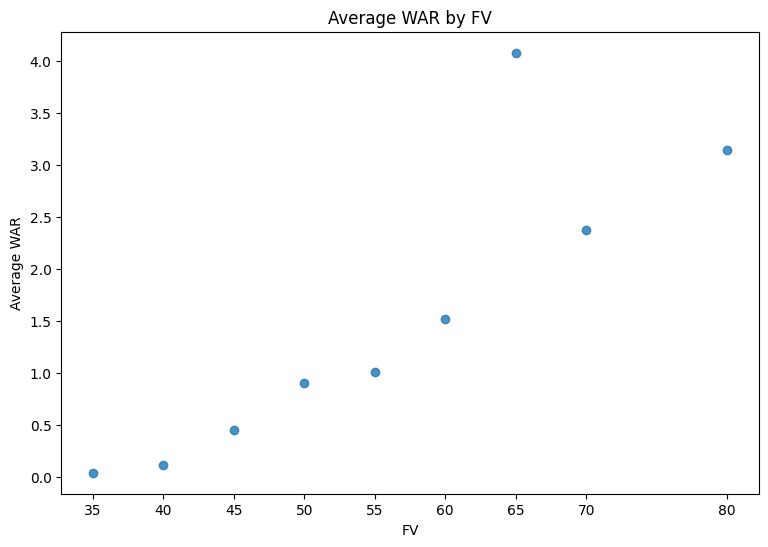

In [162]:
# Calculate average WAR for each Max Velo
WAR_FV = (clean_data.dropna(subset=["FV", "Average WAR"]).groupby("FV")["Average WAR"].mean().reset_index())
plt.figure(figsize=(9, 6))
plt.scatter(
    WAR_FV["FV"],
    WAR_FV["Average WAR"],
    alpha=0.8
)
plt.title("Average WAR by FV")
plt.xlabel("FV")
plt.ylabel("Average WAR")
plt.xticks(sorted(WAR_FV["FV"].unique()))
plt.show()

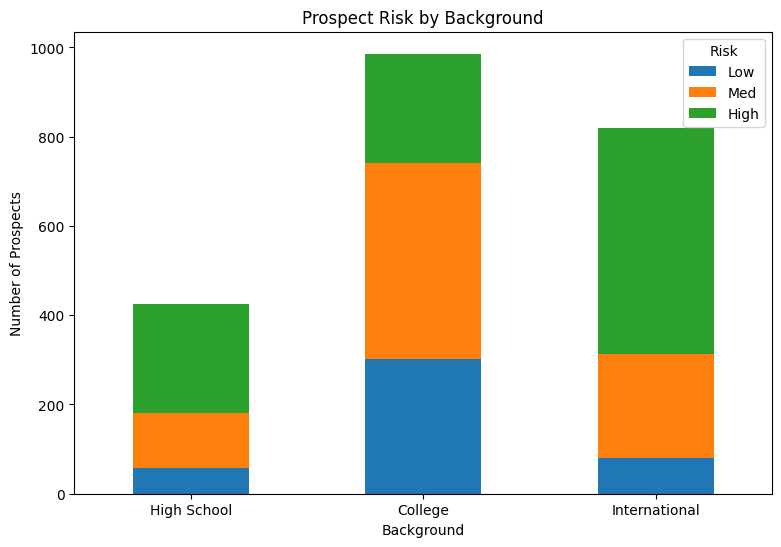

In [163]:
risk_v_background = clean_data.dropna(subset=["Background", "Risk"])
risk_counts = pd.crosstab(clean_data["Background"], clean_data["Risk"])
risk_counts = risk_counts.reindex(
    index=["High School", "College", "International"],
    columns=["Low", "Med", "High"],
    fill_value=0
)
risk_counts.plot(kind="bar", stacked=True, figsize=(9, 6))
plt.title("Prospect Risk by Background")
plt.xlabel("Background")
plt.ylabel("Number of Prospects")
plt.xticks(rotation=0)
plt.legend(title="Risk")
plt.show()

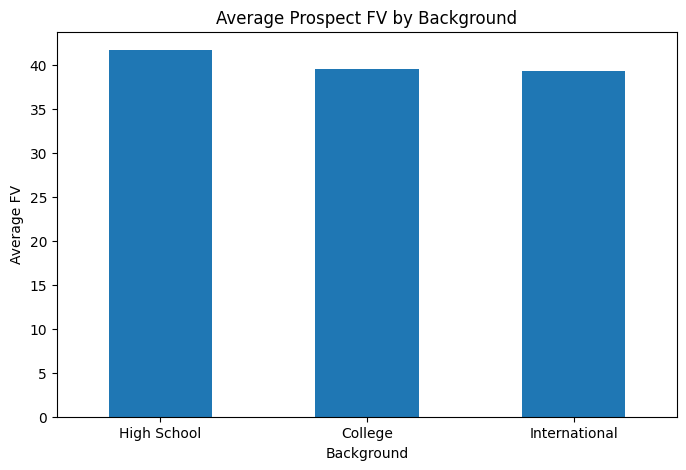

In [164]:
fev_by_background = clean_data.groupby("Background")["FV"].mean()
fev_by_background = fev_by_background.reindex(
    ["High School", "College", "International"]
)
fev_by_background.plot(kind="bar", figsize=(8, 5))
plt.title("Average Prospect FV by Background")
plt.xlabel("Background")
plt.ylabel("Average FV")
plt.xticks(rotation=0)
plt.show()

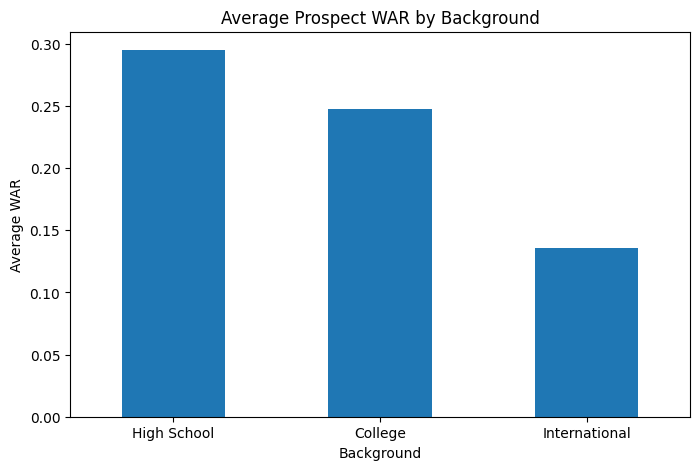

In [165]:
war_by_background = clean_data.groupby("Background")["Average WAR"].mean()
war_by_background = war_by_background.reindex(
    ["High School", "College", "International"]
)
war_by_background.plot(kind="bar", figsize=(8, 5))
plt.title("Average Prospect WAR by Background")
plt.xlabel("Background")
plt.ylabel("Average WAR")
plt.xticks(rotation=0)
plt.show()

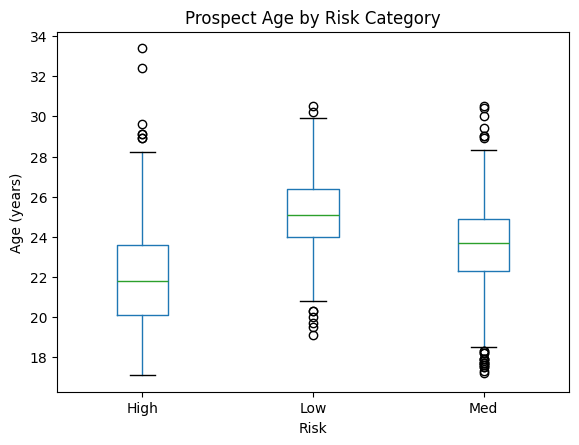

In [166]:
clean_data["Risk"] = clean_data["Risk"].replace("Short", pd.NA)
risk_order = ["Low", "Med", "High"]

clean_data.boxplot(
    column="Age",
    by="Risk",
    grid=False
)

plt.title("Prospect Age by Risk Category")
plt.suptitle("")
plt.xlabel("Risk")
plt.ylabel("Age (years)")
plt.show()

#**Plots For Question 2**

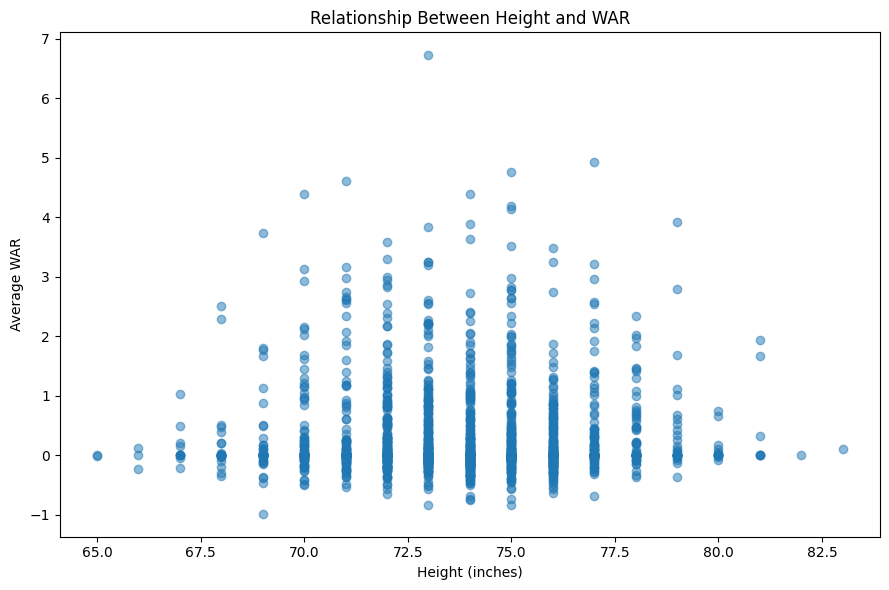

In [167]:
plot_data = clean_data.dropna(subset=["Ht", "Average WAR"])
plt.figure(figsize=(9, 6))
plt.scatter(plot_data["Ht"], plot_data["Average WAR"], alpha=0.5)
plt.title("Relationship Between Height and WAR")
plt.xlabel("Height (inches)")
plt.ylabel("Average WAR")
plt.tight_layout()
plt.show()

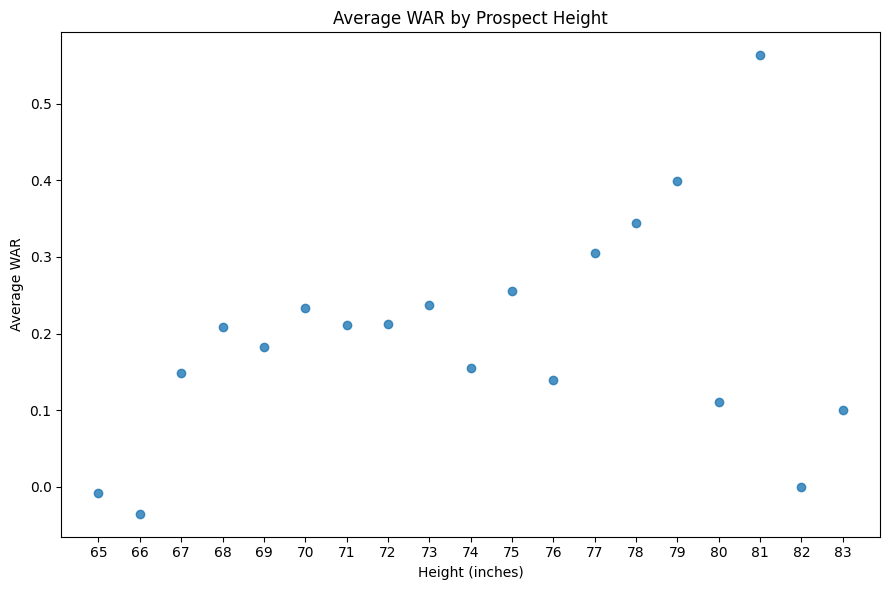

In [168]:
# Calculate average WAR for each height
avg_war_height = (
    clean_data.dropna(subset=["Ht", "Average WAR"]).groupby("Ht")["Average WAR"].mean().reset_index()
)
plt.figure(figsize=(9, 6))
plt.scatter(
    avg_war_height["Ht"],
    avg_war_height["Average WAR"],
    alpha=0.8
)

plt.title("Average WAR by Prospect Height")
plt.xlabel("Height (inches)")
plt.ylabel("Average WAR")
plt.xticks(sorted(avg_war_height["Ht"].unique()))
plt.tight_layout()
plt.show()

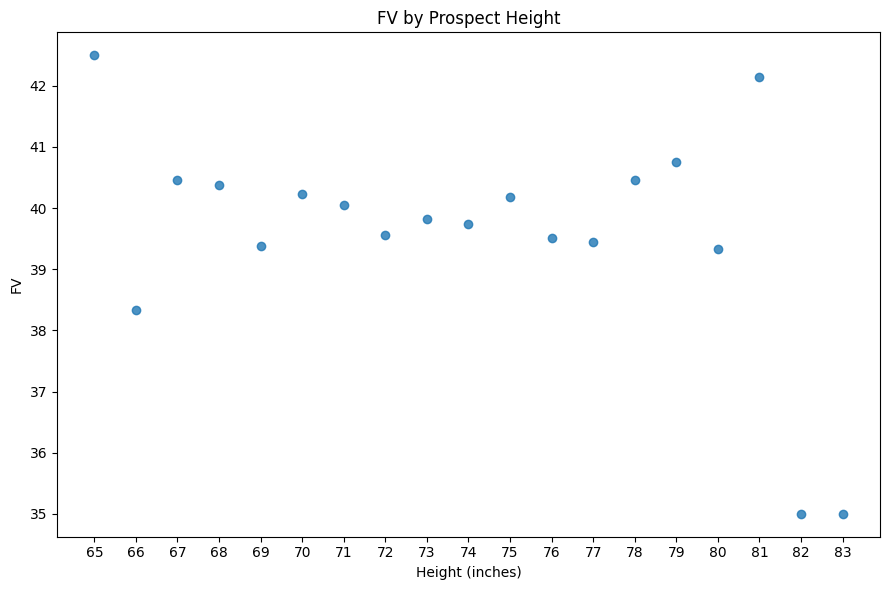

In [169]:
# Calculate average FV for each height
FV_height = (
    clean_data.dropna(subset=["Ht", "FV"]).groupby("Ht")["FV"].mean().reset_index()
)
plt.figure(figsize=(9, 6))
plt.scatter(
    FV_height["Ht"],
    FV_height["FV"],
    alpha=0.8
)

plt.title("FV by Prospect Height")
plt.xlabel("Height (inches)")
plt.ylabel("FV")
plt.xticks(sorted(FV_height["Ht"].unique()))
plt.tight_layout()
plt.show()

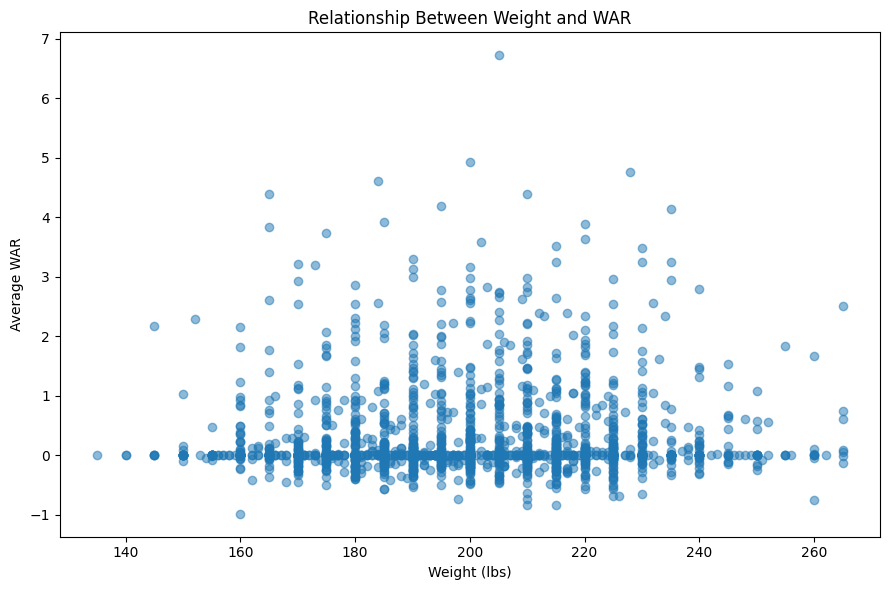

In [170]:
plot_data = clean_data.dropna(subset=["Wt", "Average WAR"])
plt.figure(figsize=(9, 6))
plt.scatter(plot_data["Wt"], plot_data["Average WAR"], alpha=0.5)
plt.title("Relationship Between Weight and WAR")
plt.xlabel("Weight (lbs)")
plt.ylabel("Average WAR")
plt.tight_layout()
plt.show()

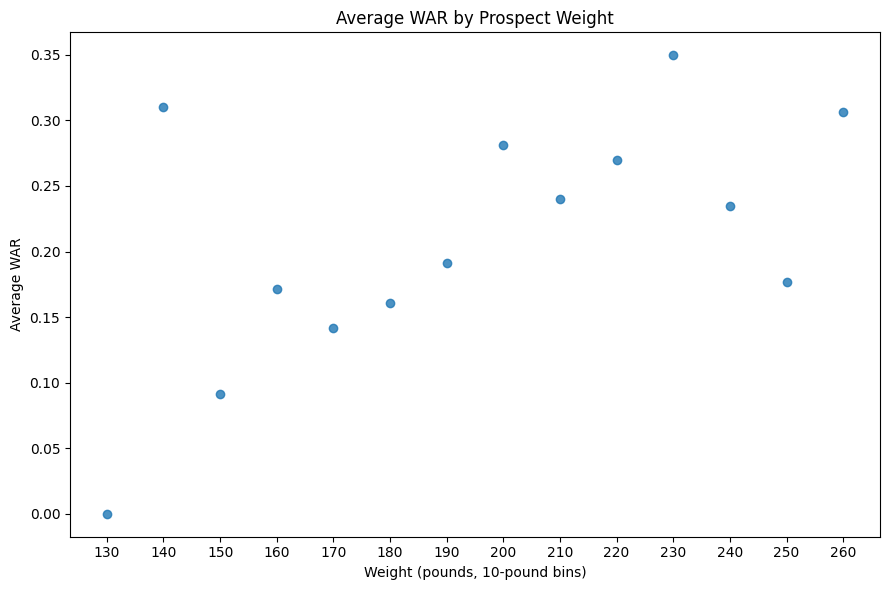

In [171]:
# Create 10-pound weight bins
clean_data["Wt_Bin"] = (
    np.floor(clean_data["Wt"] / 10) * 10
)
# Calculate average WAR for each weight bin
WAR_weight = (
    clean_data.dropna(subset=["Wt_Bin", "Average WAR"]).groupby("Wt_Bin")["Average WAR"].mean().reset_index()
)
plt.figure(figsize=(9, 6))
plt.scatter(
    WAR_weight["Wt_Bin"],
    WAR_weight["Average WAR"],
    alpha=0.8
)

plt.title("Average WAR by Prospect Weight")
plt.xlabel("Weight (pounds, 10-pound bins)")
plt.ylabel("Average WAR")
plt.xticks(sorted(WAR_weight["Wt_Bin"].unique()))
plt.tight_layout()
plt.show()

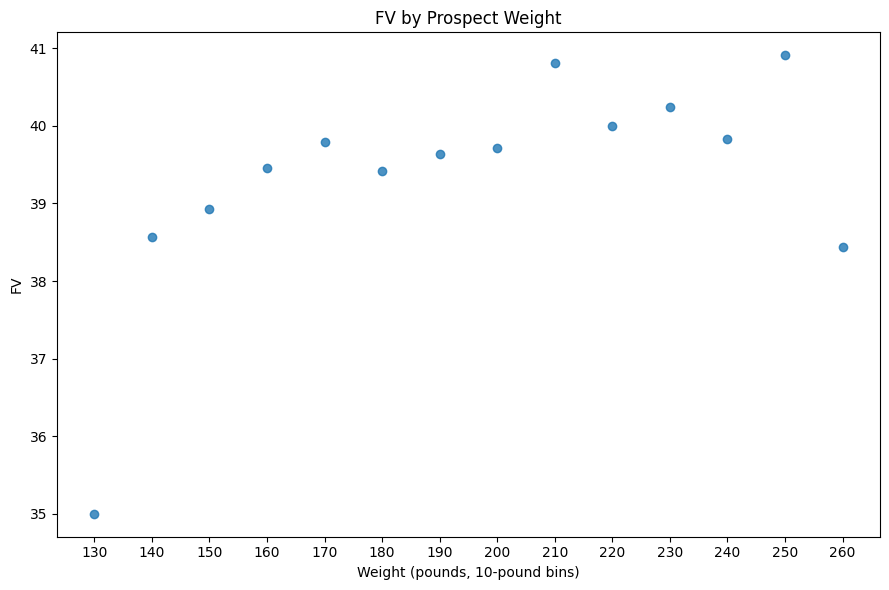

In [172]:
# Create 10-pound weight bins
clean_data["Wt_Bin"] = (
    np.floor(clean_data["Wt"] / 10) * 10
)
# Calculate average FV for each weight bin
FV_weight = (
    clean_data.dropna(subset=["Wt_Bin", "FV"]).groupby("Wt_Bin")["FV"].mean().reset_index()
)
plt.figure(figsize=(9, 6))
plt.scatter(
    FV_weight["Wt_Bin"],
    FV_weight["FV"],
    alpha=0.8
)

plt.title("FV by Prospect Weight")
plt.xlabel("Weight (pounds, 10-pound bins)")
plt.ylabel("FV")
plt.xticks(sorted(FV_weight["Wt_Bin"].unique()))
plt.tight_layout()
plt.show()

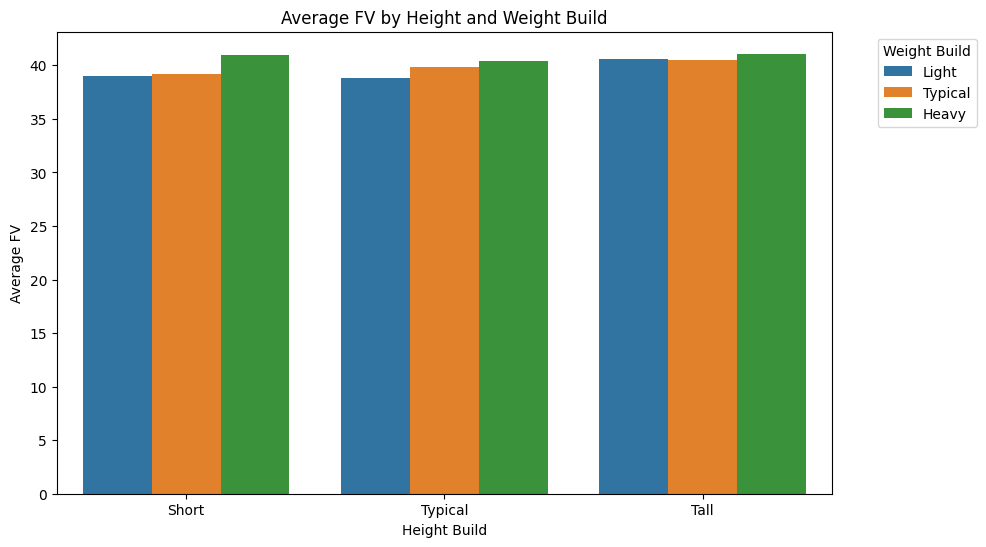

In [173]:
height_order = ["Short", "Typical", "Tall"]
weight_order = ["Light", "Typical", "Heavy"]
plt.figure(figsize=(10, 6))
sns.barplot(
    data=clean_data,
    x="Height Build",
    y="FV",
    hue="Weight Build",
    order=height_order,
    hue_order=weight_order,
    errorbar=None
)
plt.title("Average FV by Height and Weight Build")
plt.xlabel("Height Build")
plt.ylabel("Average FV")
plt.legend(title="Weight Build", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

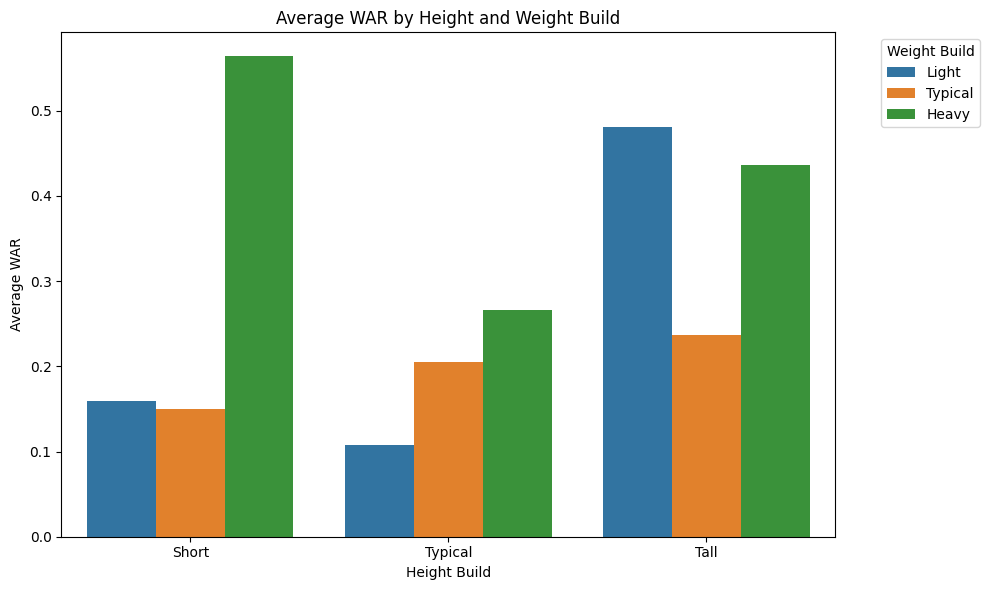

In [174]:
height_order = ["Short", "Typical", "Tall"]
weight_order = ["Light", "Typical", "Heavy"]

plt.figure(figsize=(10, 6))
sns.barplot(
    data=clean_data,
    x="Height Build",
    y="Average WAR",
    hue="Weight Build",
    order=height_order,
    hue_order=weight_order,
    errorbar=None
)
plt.title("Average WAR by Height and Weight Build")
plt.xlabel("Height Build")
plt.ylabel("Average WAR")
plt.legend(title="Weight Build", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

#**Plots for Question 3**

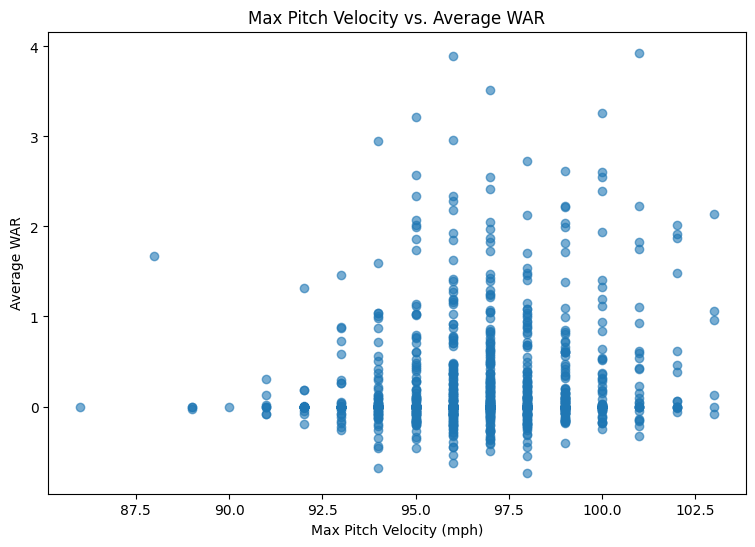

In [175]:
plot_data = clean_data.dropna(subset=["Tops", "Average WAR"])
plt.figure(figsize=(9, 6))
plt.scatter(plot_data["Tops"], plot_data["Average WAR"], alpha=0.6)
plt.title("Max Pitch Velocity vs. Average WAR")
plt.xlabel("Max Pitch Velocity (mph)")
plt.ylabel("Average WAR")
plt.show()

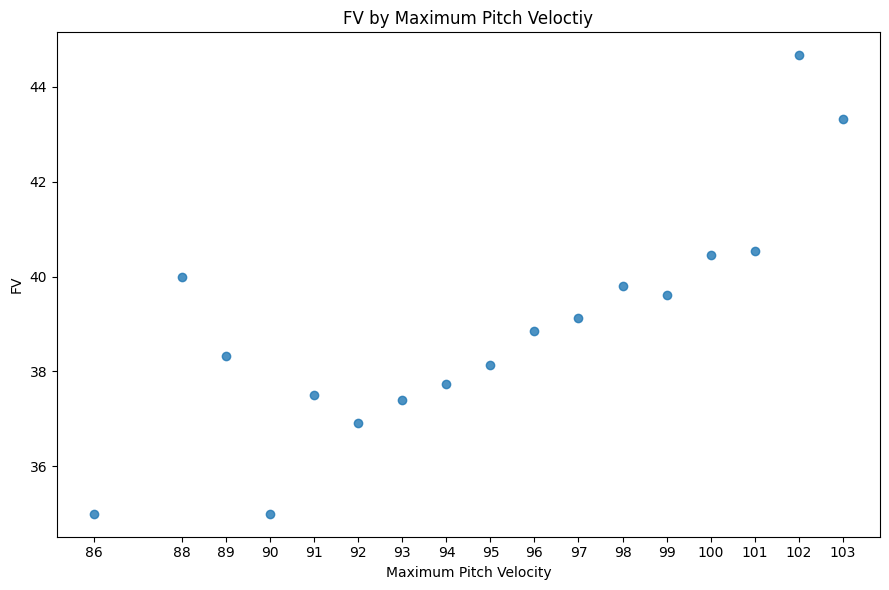

In [176]:
# Calculate average FV for MPH
FV_velo = (
    clean_data.dropna(subset=["Tops", "FV"]).groupby("Tops")["FV"].mean().reset_index()
)
plt.figure(figsize=(9, 6))
plt.scatter(
    FV_velo["Tops"],
    FV_velo["FV"],
    alpha=0.8
)

plt.title("FV by Maximum Pitch Veloctiy")
plt.xlabel("Maximum Pitch Velocity")
plt.ylabel("FV")
plt.xticks(sorted(FV_velo["Tops"].unique()))
plt.tight_layout()
plt.show()

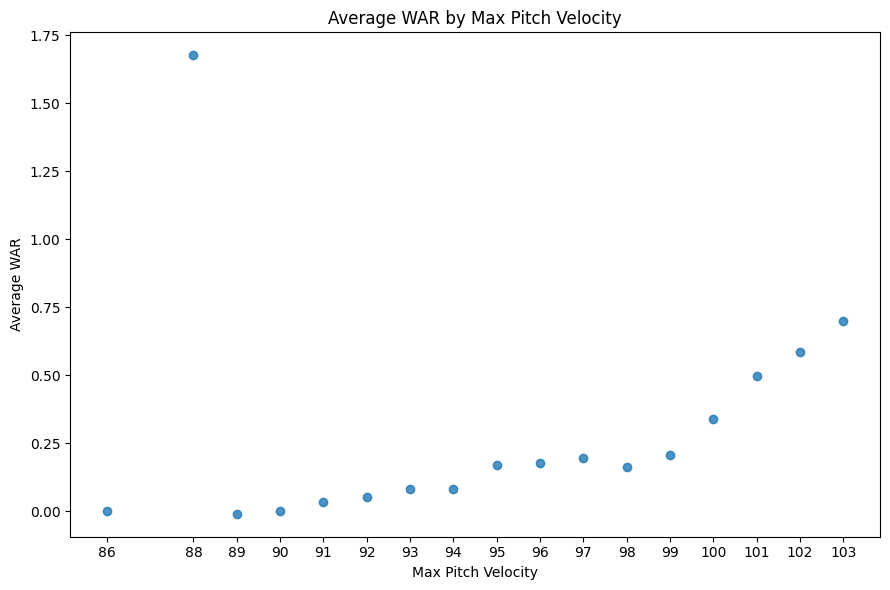

In [177]:
# Calculate average WAR for each Max Velo
WAR_velo = (clean_data.dropna(subset=["Tops", "Average WAR"]).groupby("Tops")["Average WAR"].mean().reset_index())
plt.figure(figsize=(9, 6))
plt.scatter(
    WAR_velo["Tops"],
    WAR_velo["Average WAR"],
    alpha=0.8
)

plt.title("Average WAR by Max Pitch Velocity")
plt.xlabel("Max Pitch Velocity")
plt.ylabel("Average WAR")
plt.xticks(sorted(WAR_velo["Tops"].unique()))
plt.tight_layout()
plt.show()

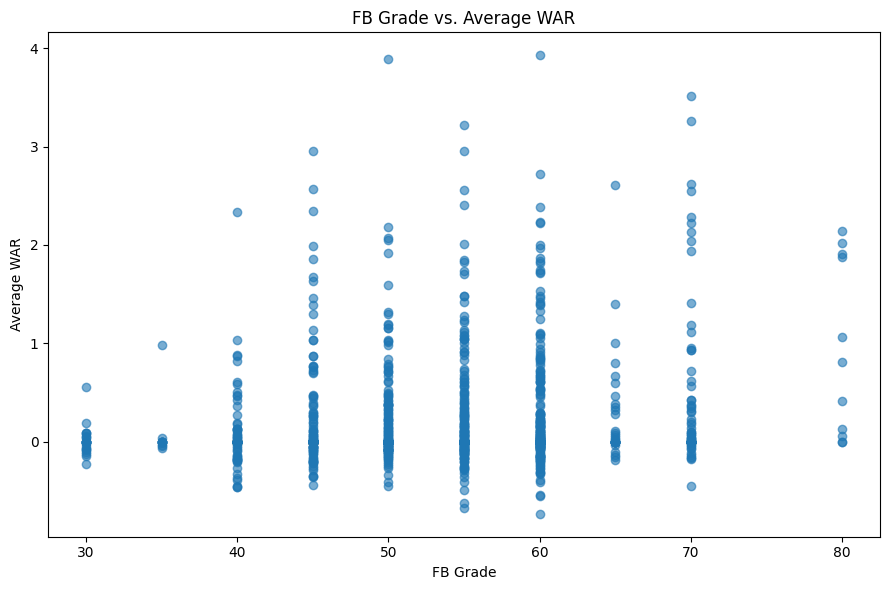

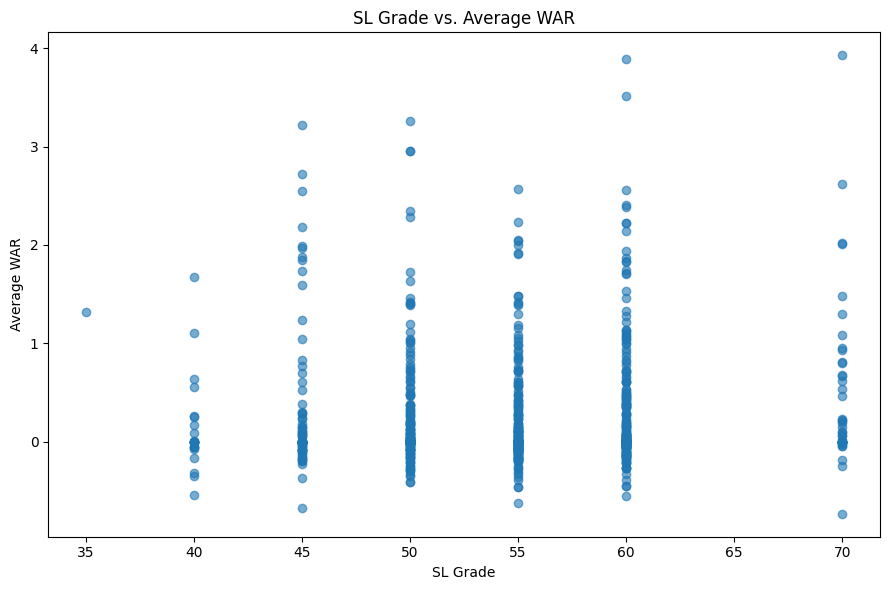

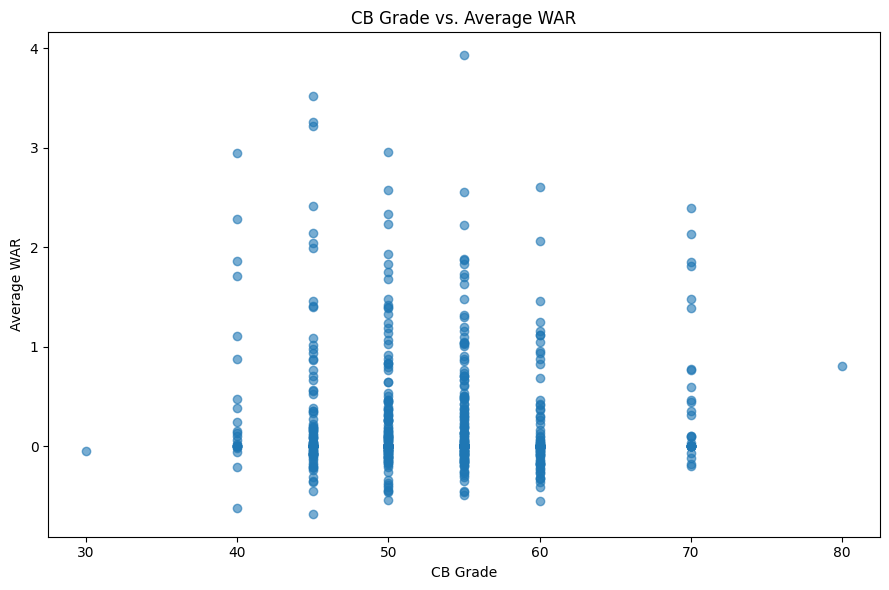

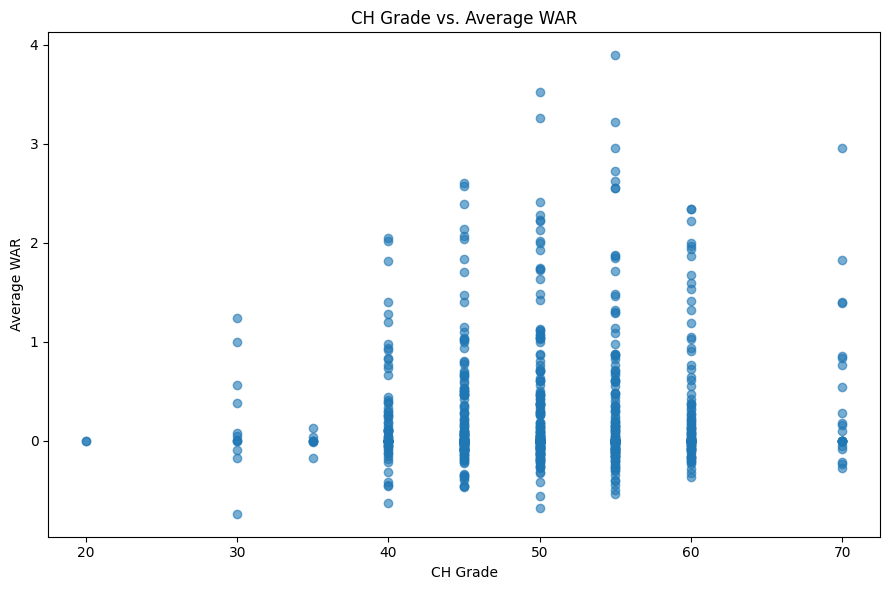

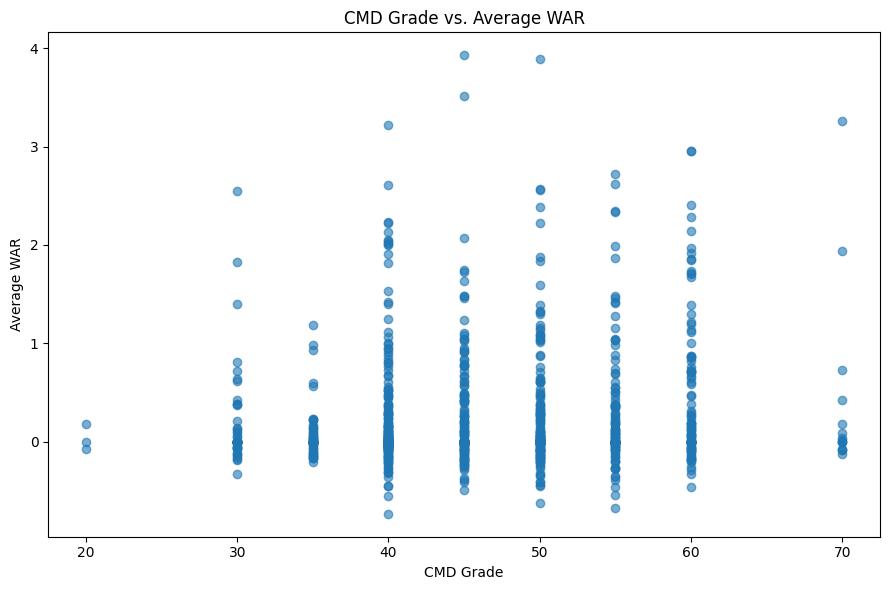

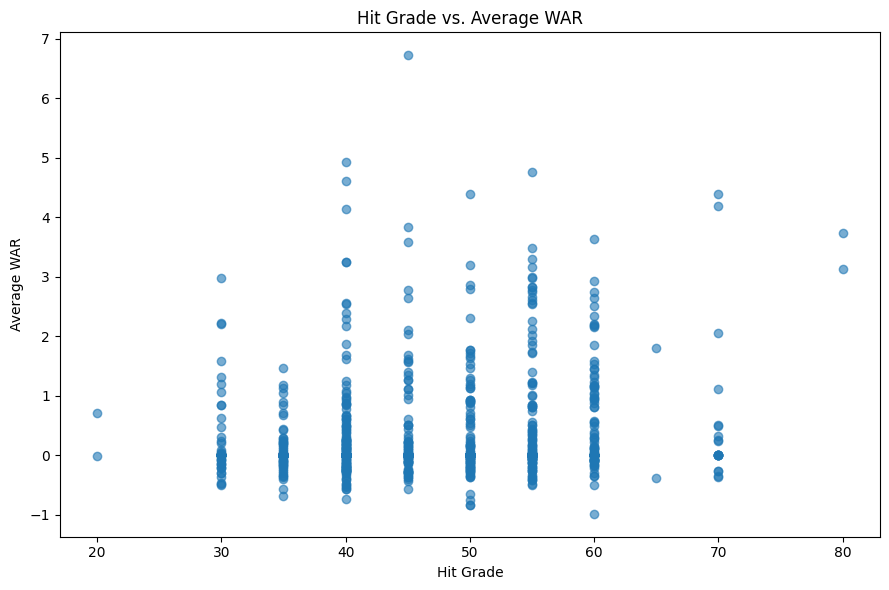

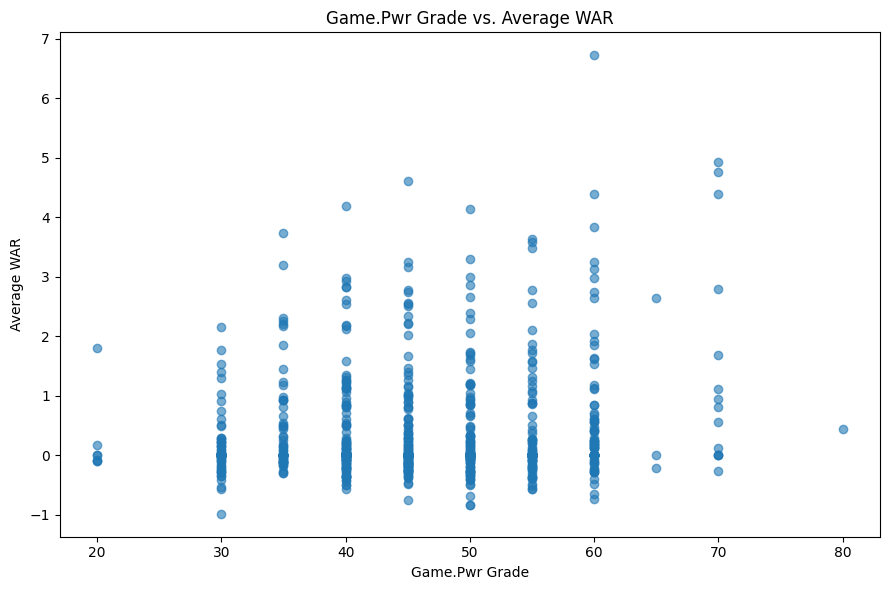

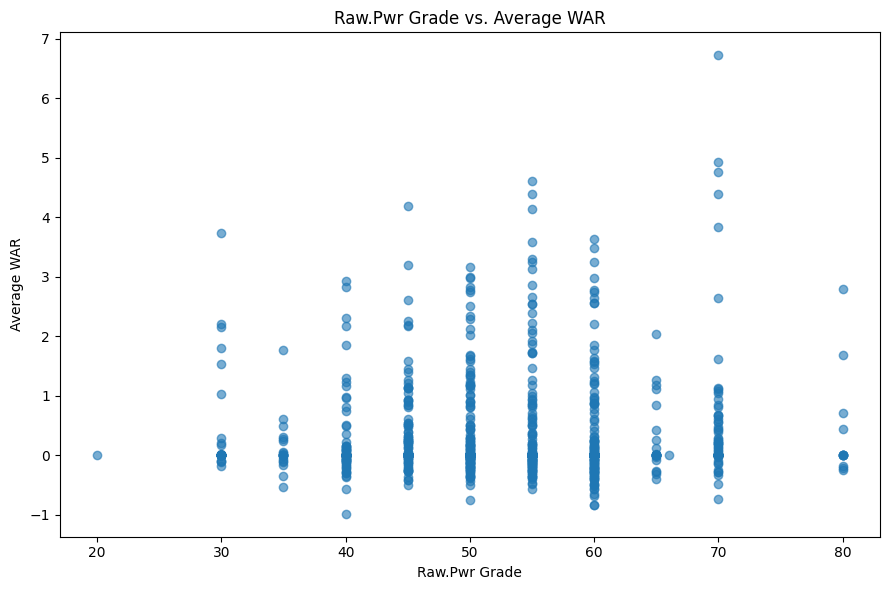

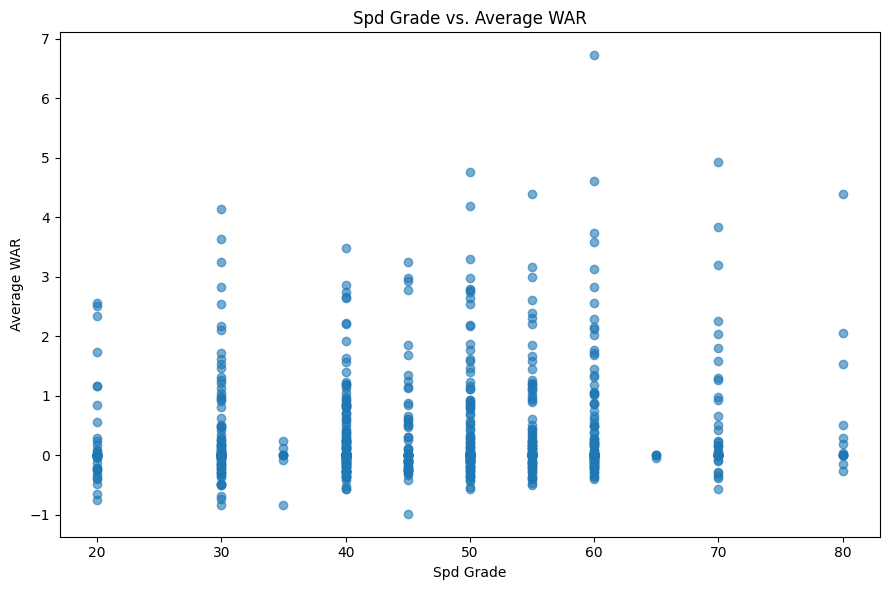

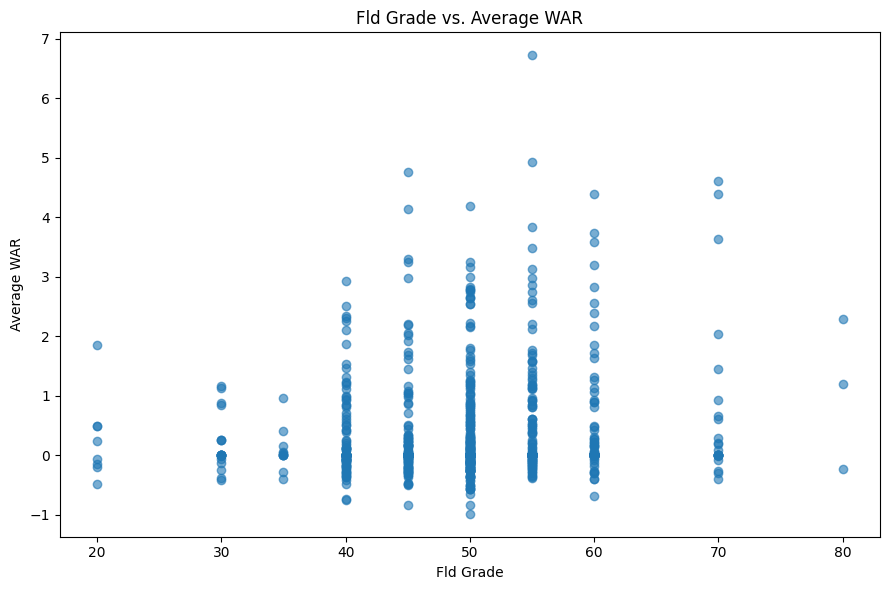

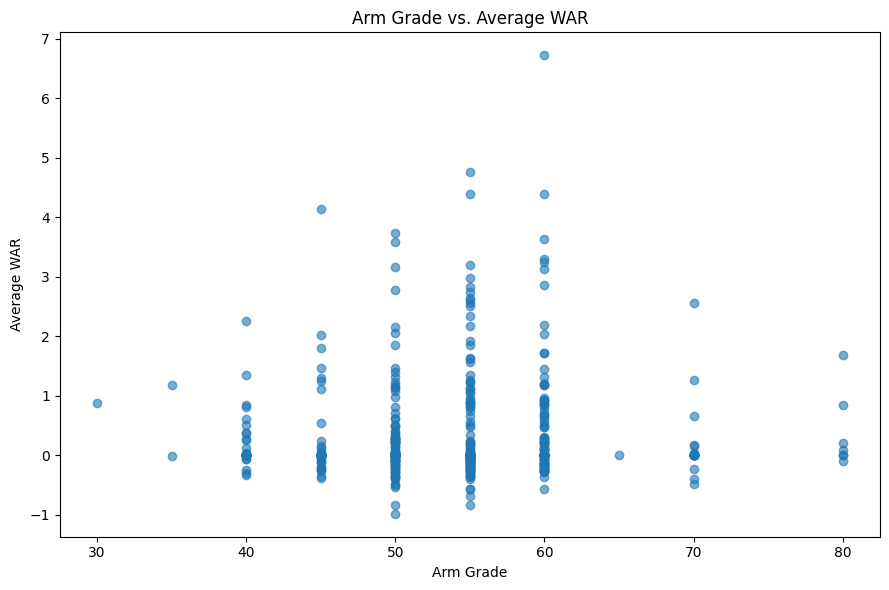

In [178]:
for grade in grade_columns:
    plot_data = clean_data.dropna(subset=[grade, "Average WAR"])
    plt.figure(figsize=(9, 6))
    plt.scatter(
        plot_data[grade],
        plot_data["Average WAR"],
        alpha=0.6
    )
    plt.title(f"{grade} Grade vs. Average WAR")
    plt.xlabel(f"{grade} Grade")
    plt.ylabel("Average WAR")
    plt.tight_layout()
    plt.show()

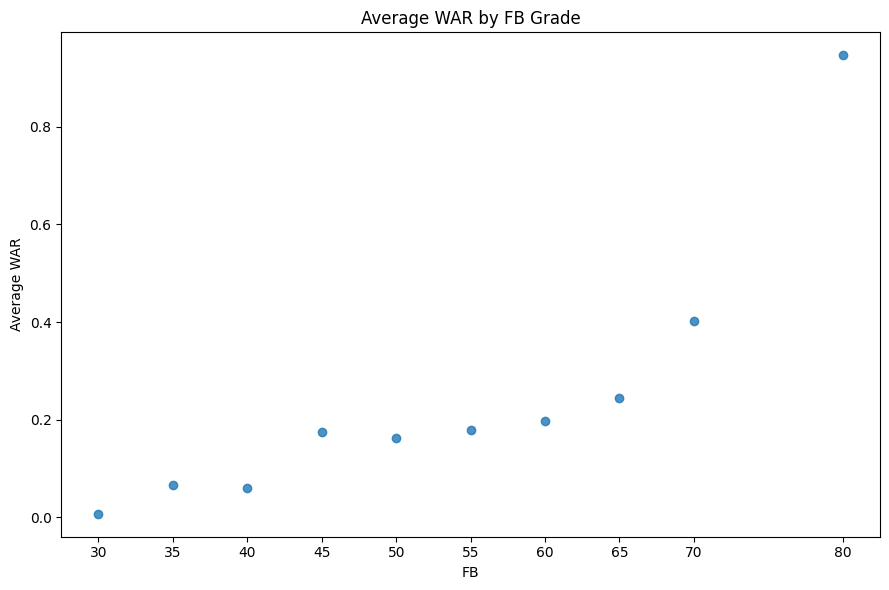

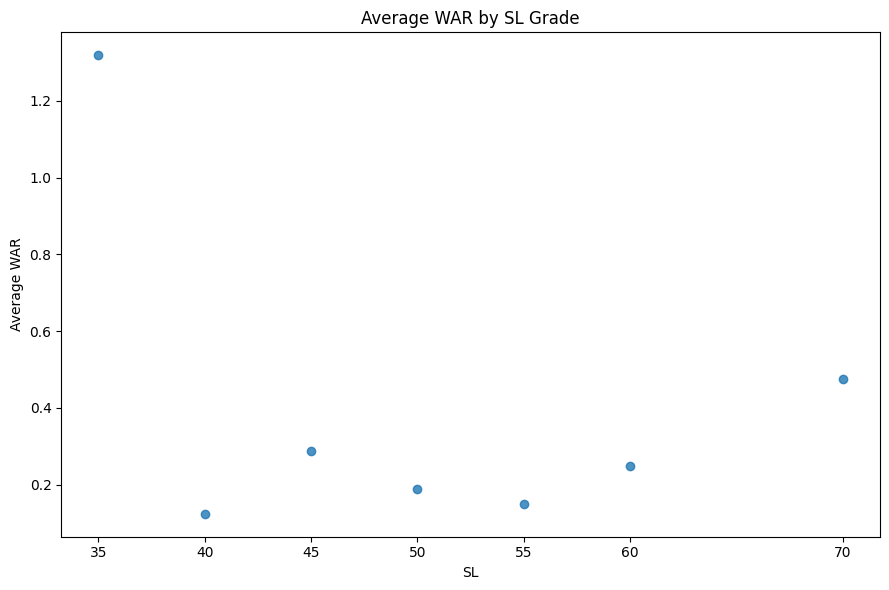

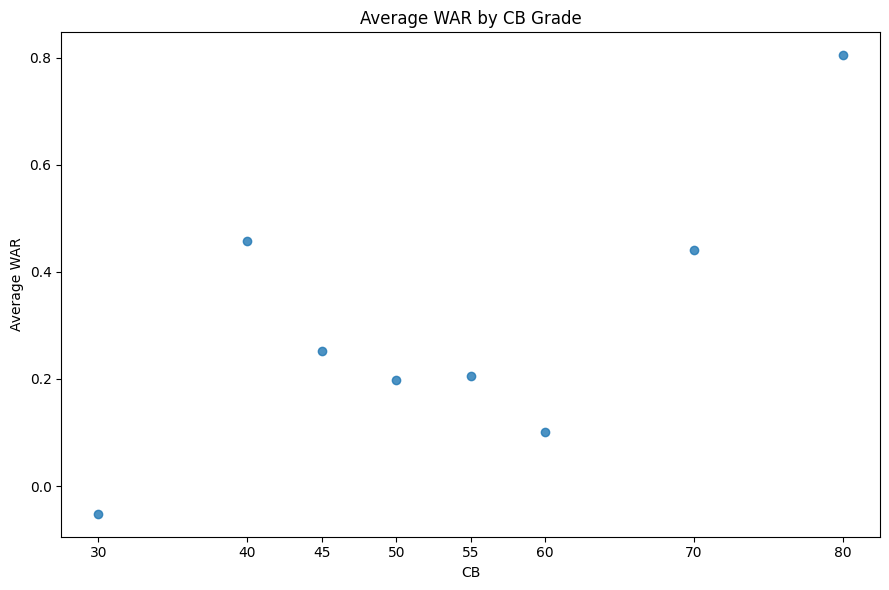

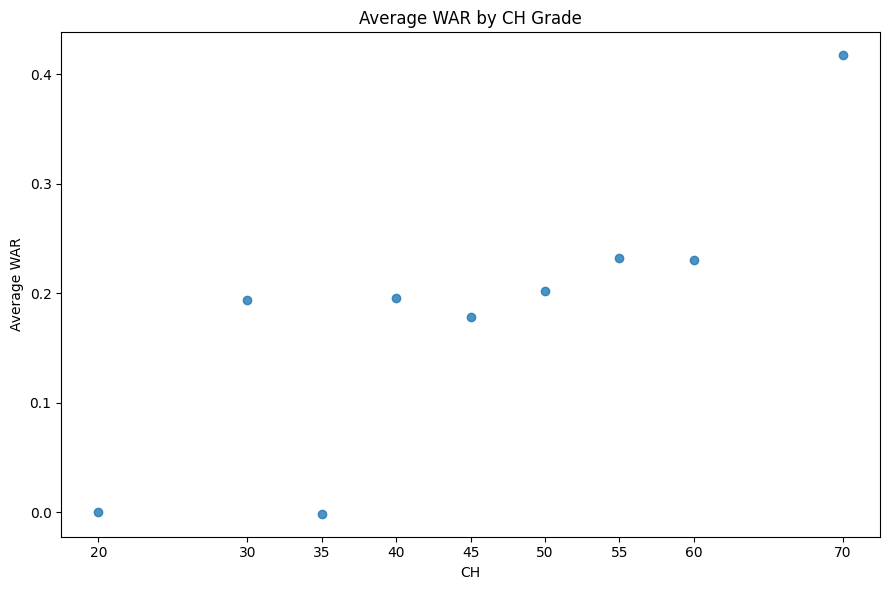

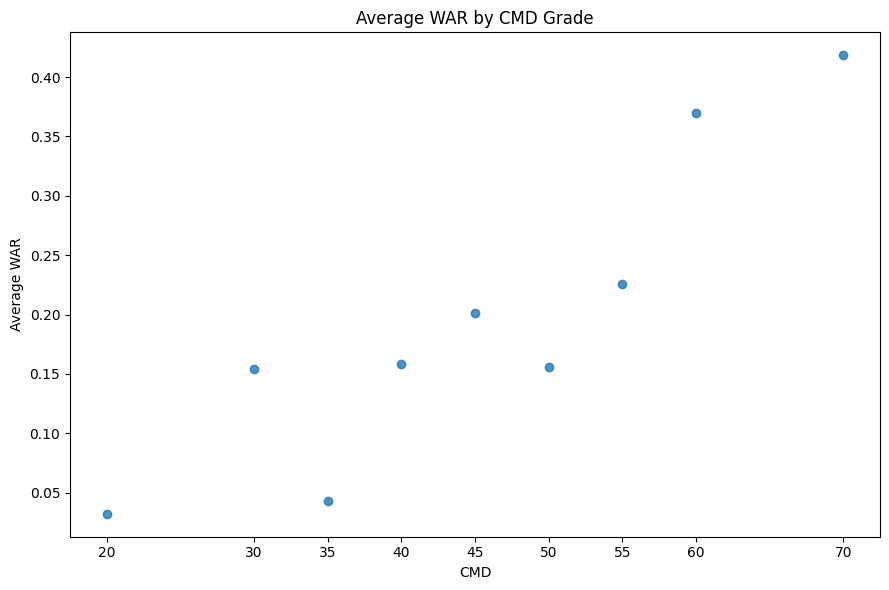

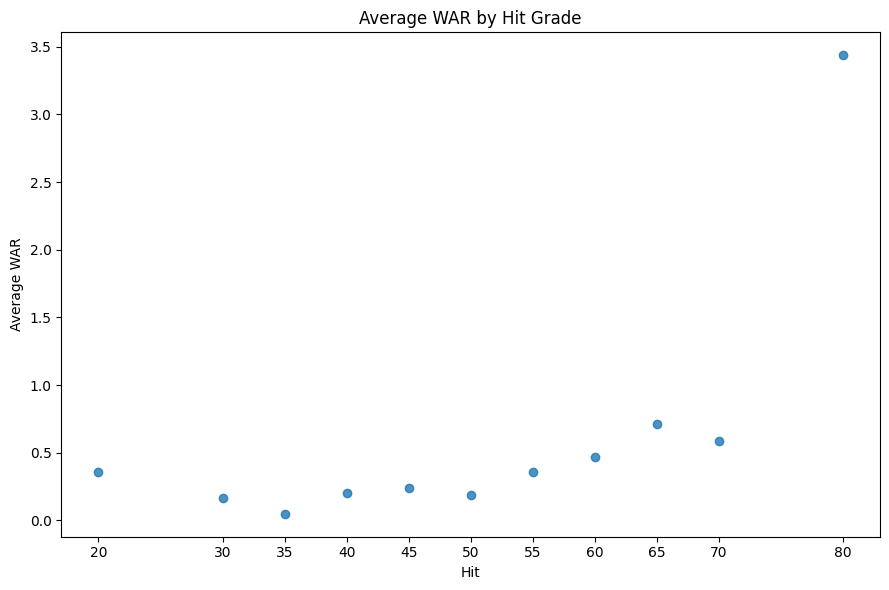

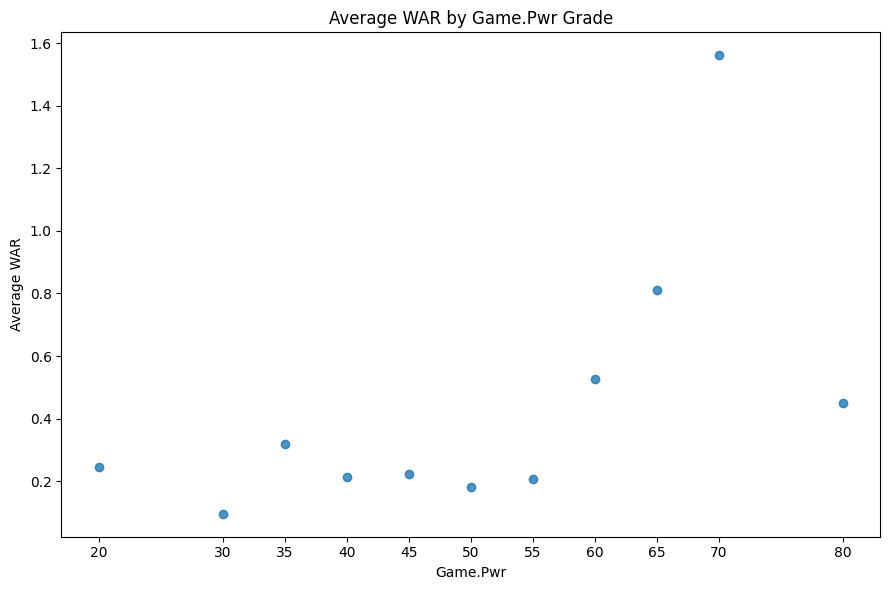

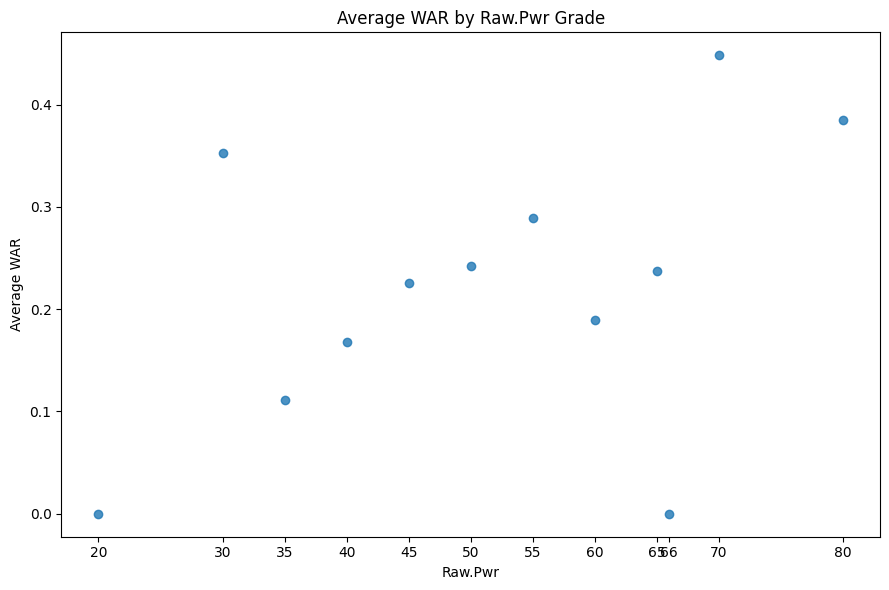

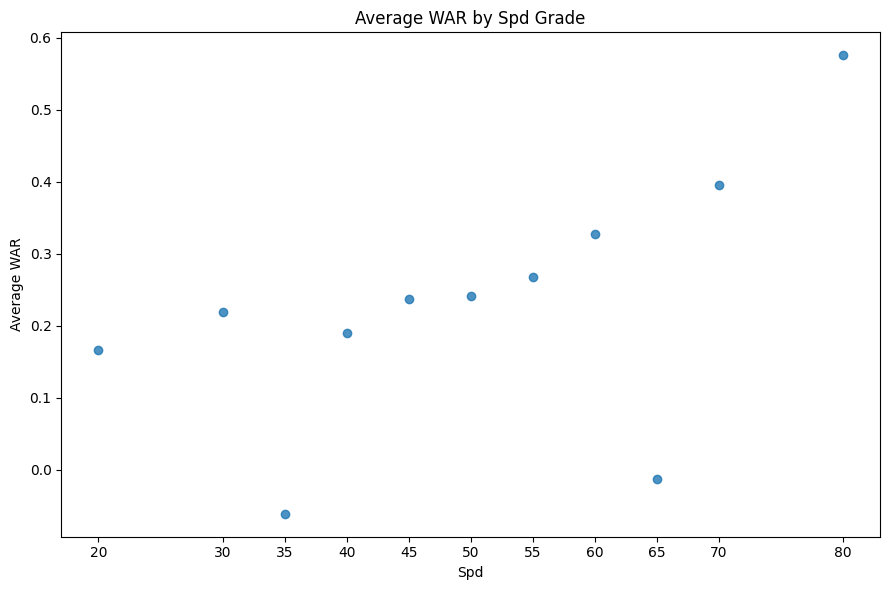

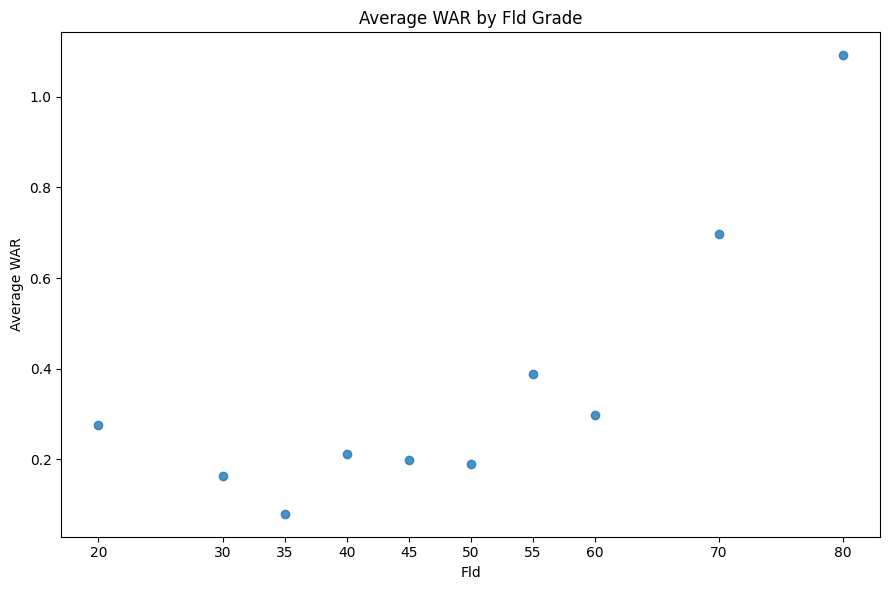

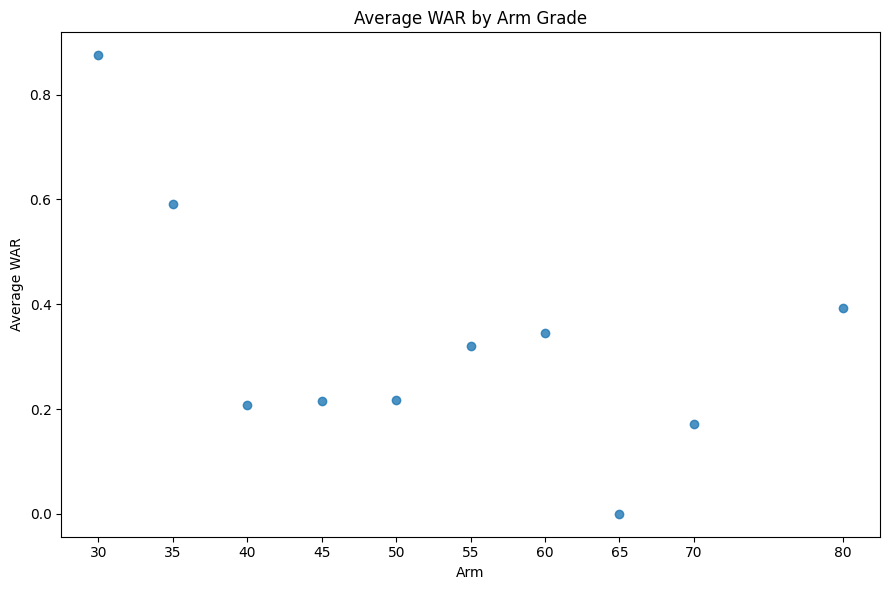

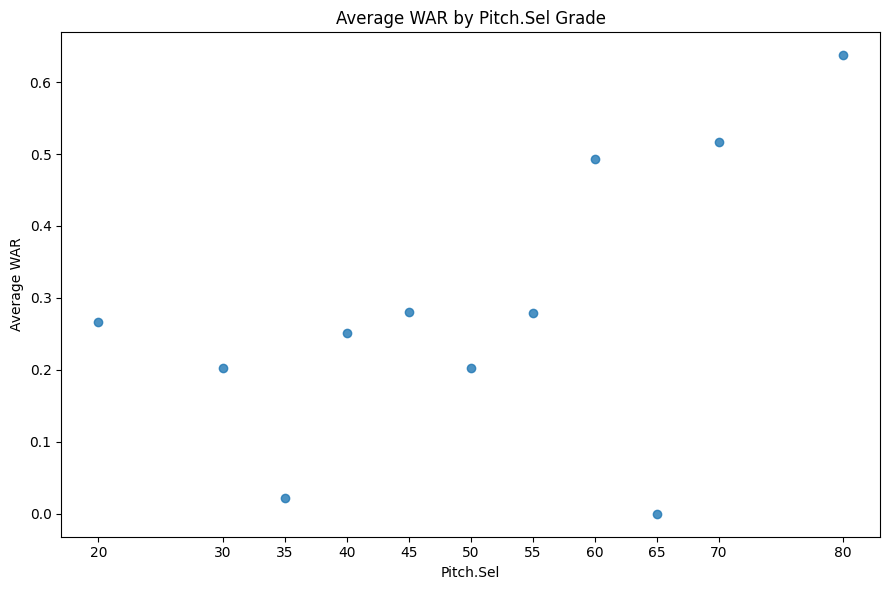

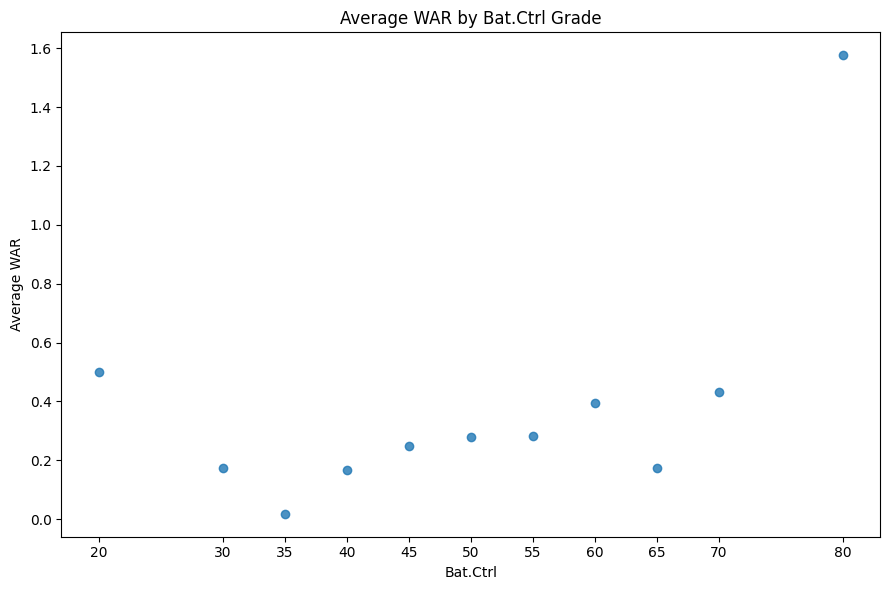

In [179]:
grade_columns = [
    "FB", "SL", "CB", "CH", "CMD",
    "Hit", "Game.Pwr", "Raw.Pwr",
    "Spd", "Fld", "Arm", "Pitch.Sel", "Bat.Ctrl"
]

for grade in grade_columns:
    WAR_grade = (
        clean_data.dropna(subset=[grade, "Average WAR"])
        .groupby(grade)["Average WAR"]
        .mean()
        .reset_index()
    )

    plt.figure(figsize=(9, 6))
    plt.scatter(
        WAR_grade[grade],
        WAR_grade["Average WAR"],
        alpha=0.8
    )

    plt.title(f"Average WAR by {grade} Grade")
    plt.xlabel(grade)
    plt.ylabel("Average WAR")
    plt.xticks(sorted(WAR_grade[grade].unique()))
    plt.tight_layout()
    plt.show()

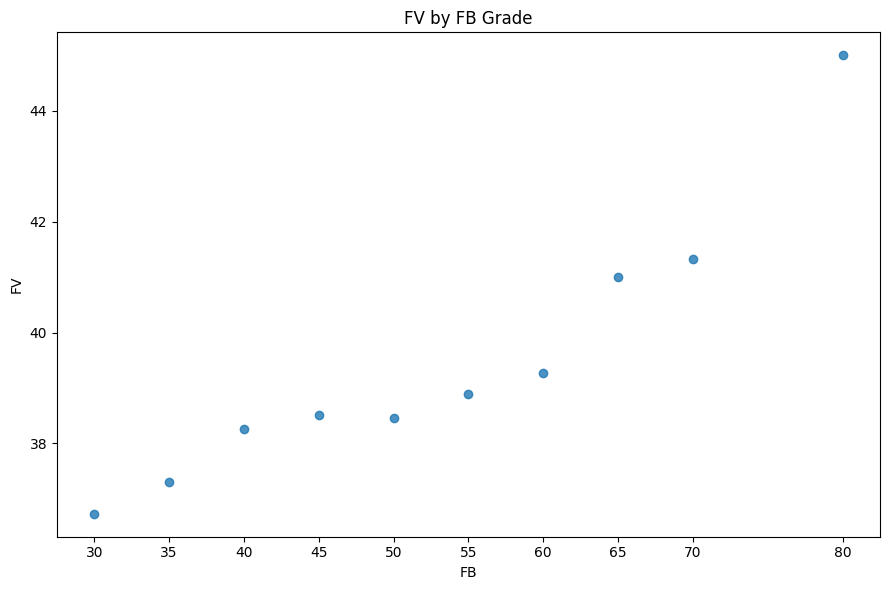

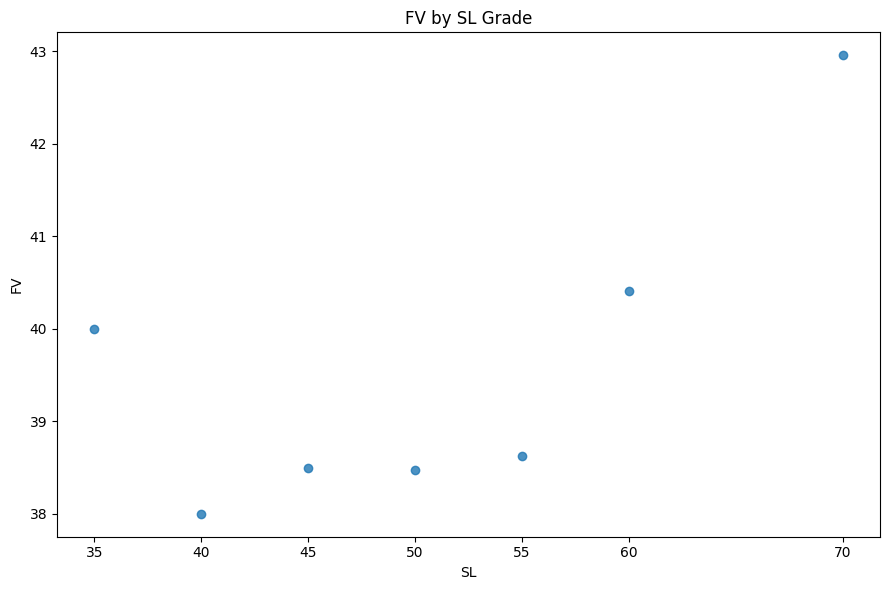

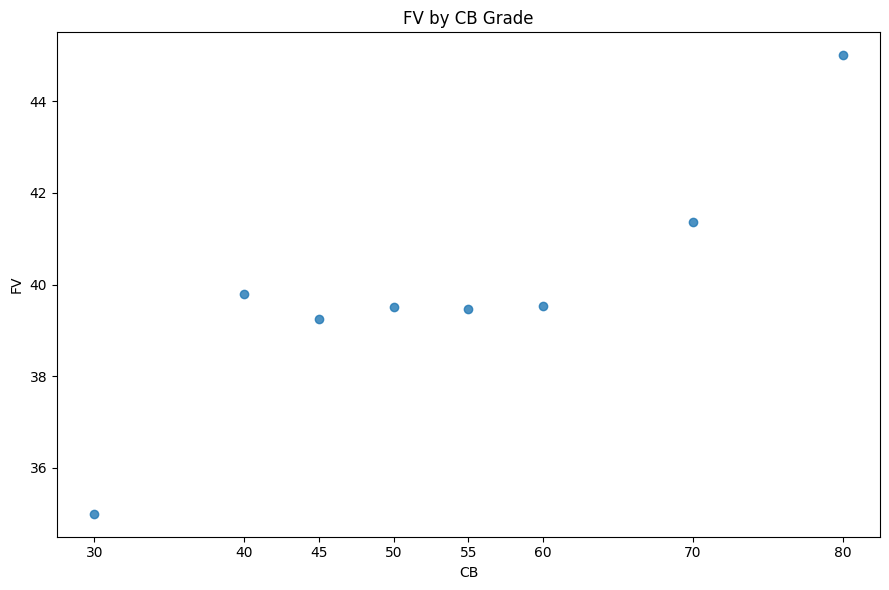

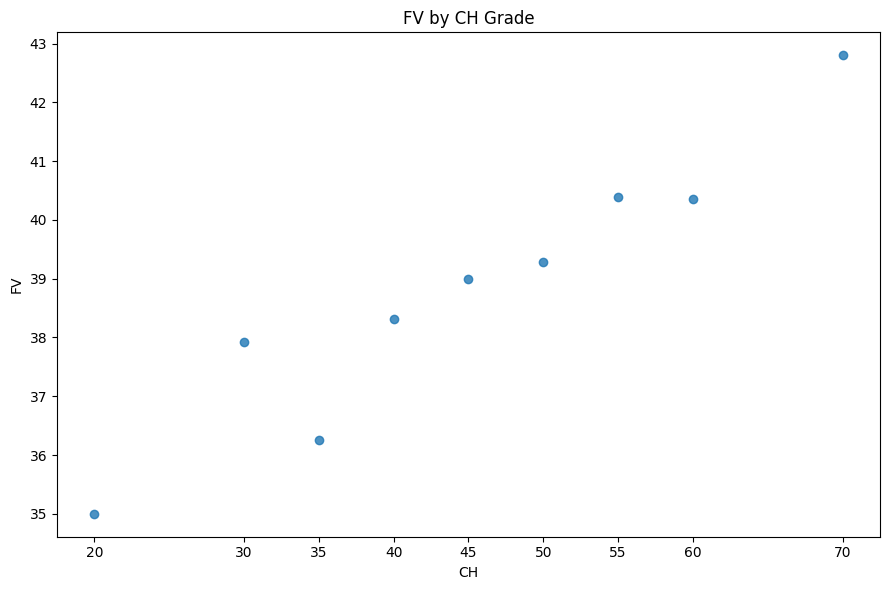

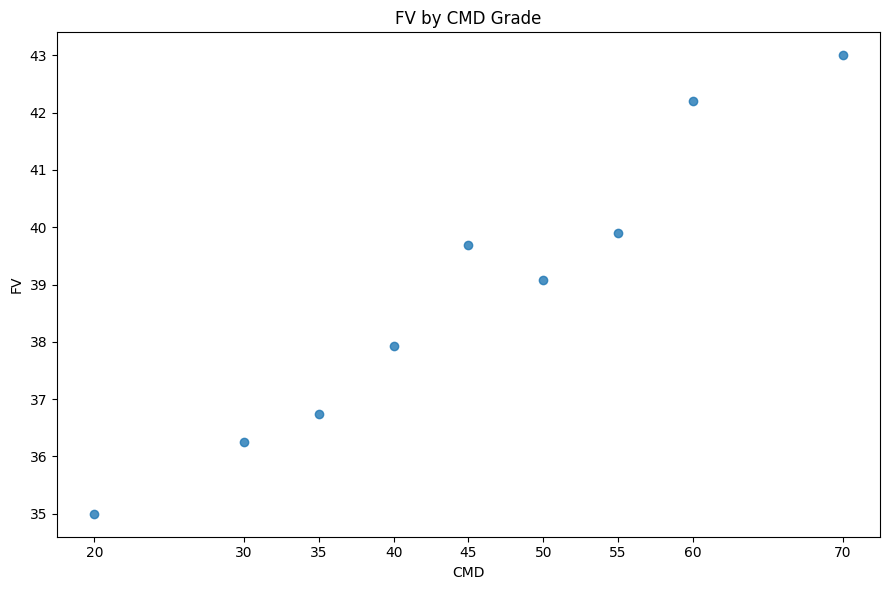

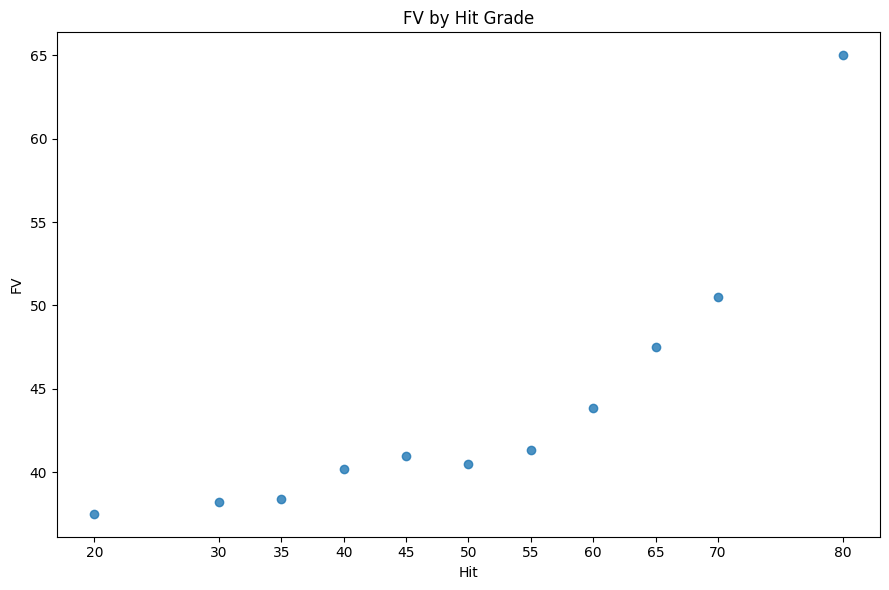

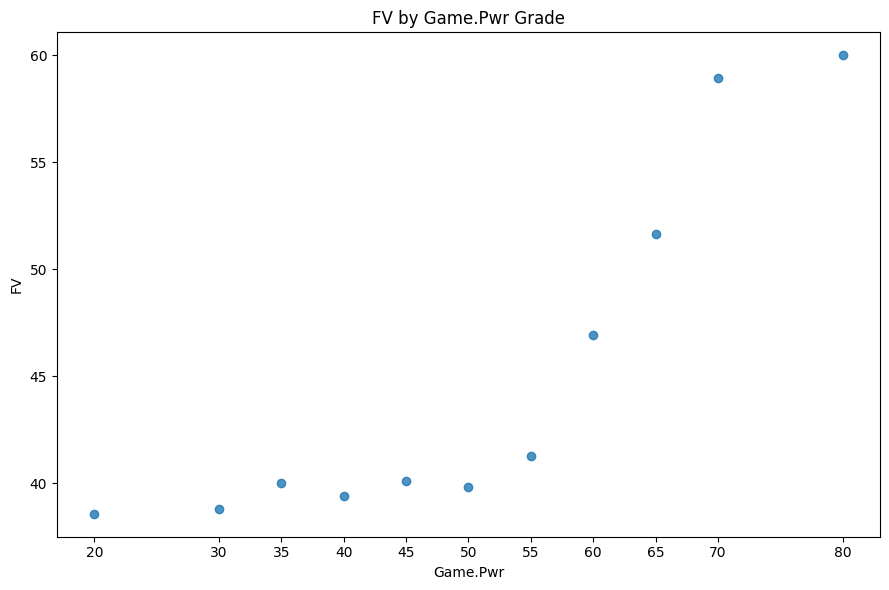

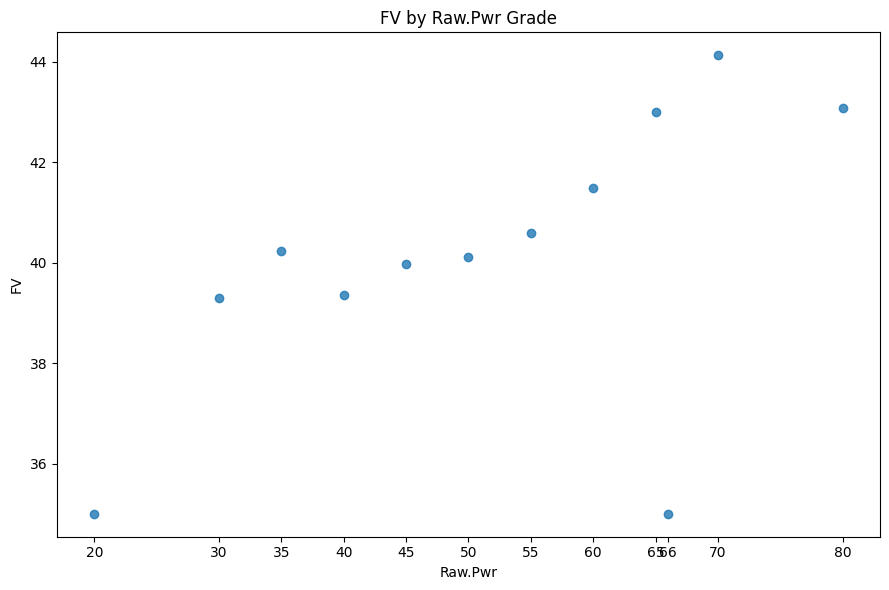

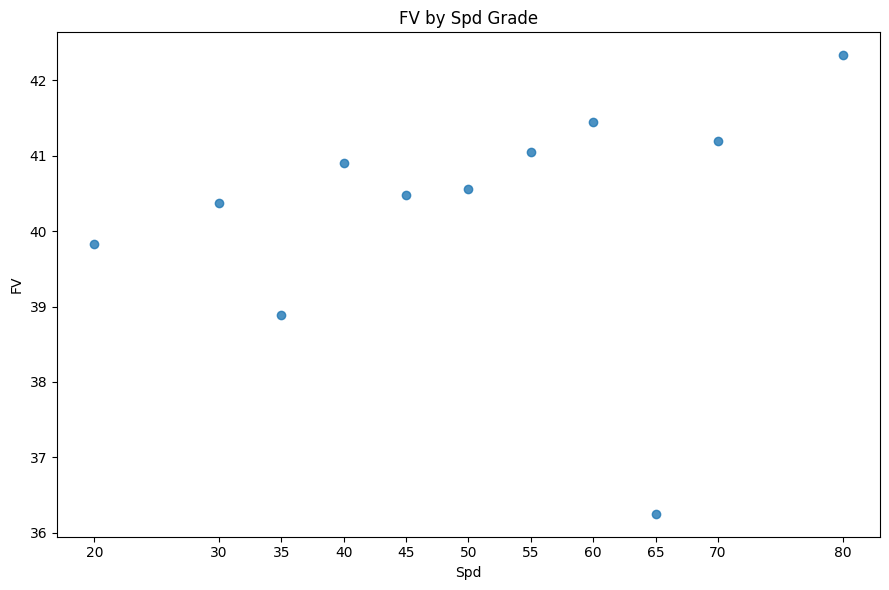

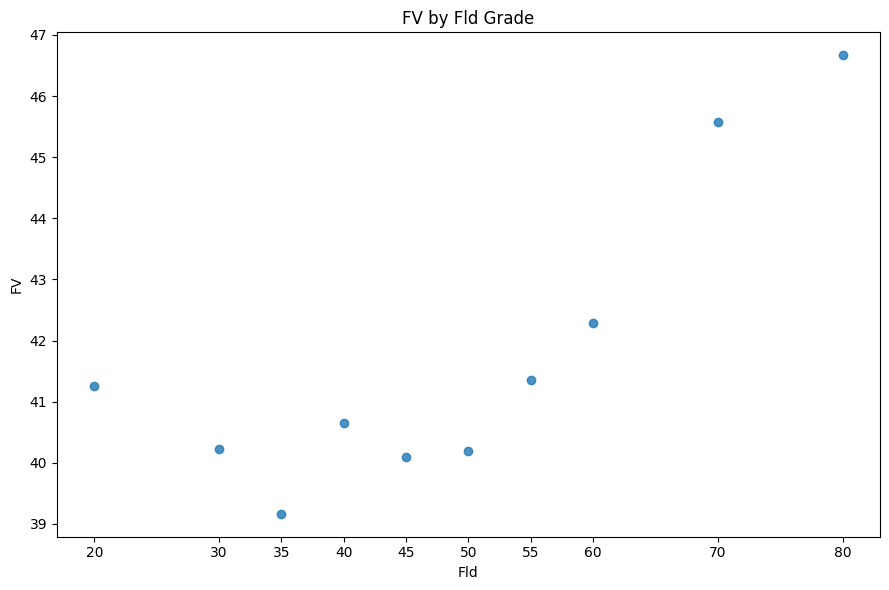

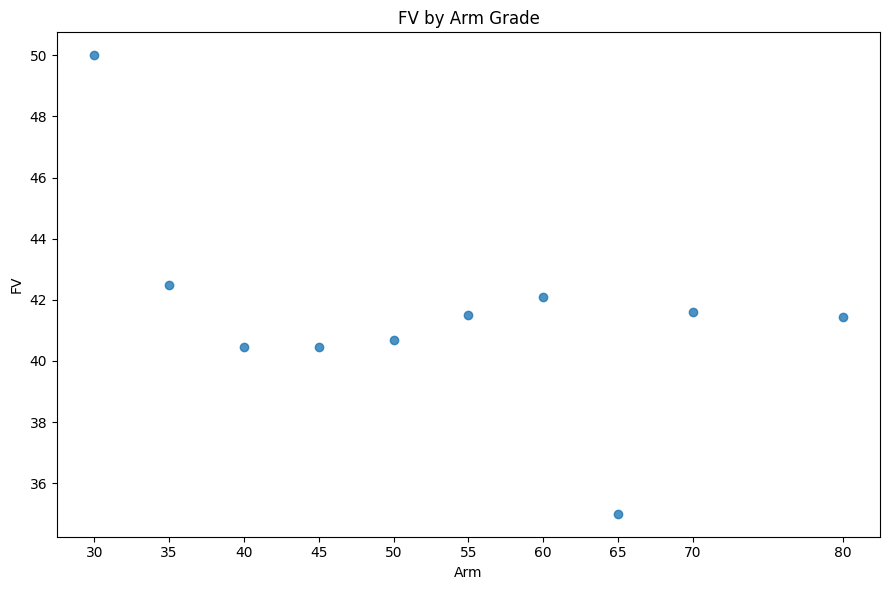

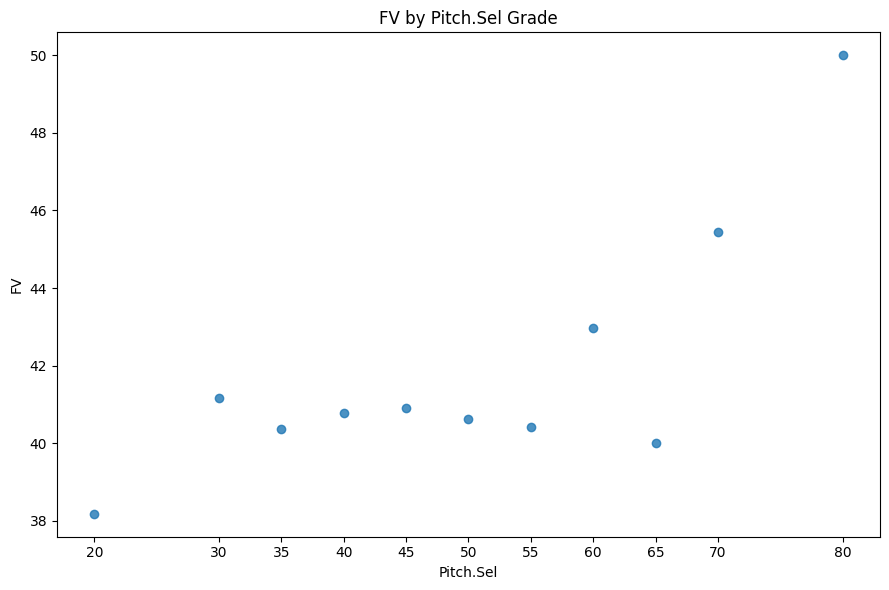

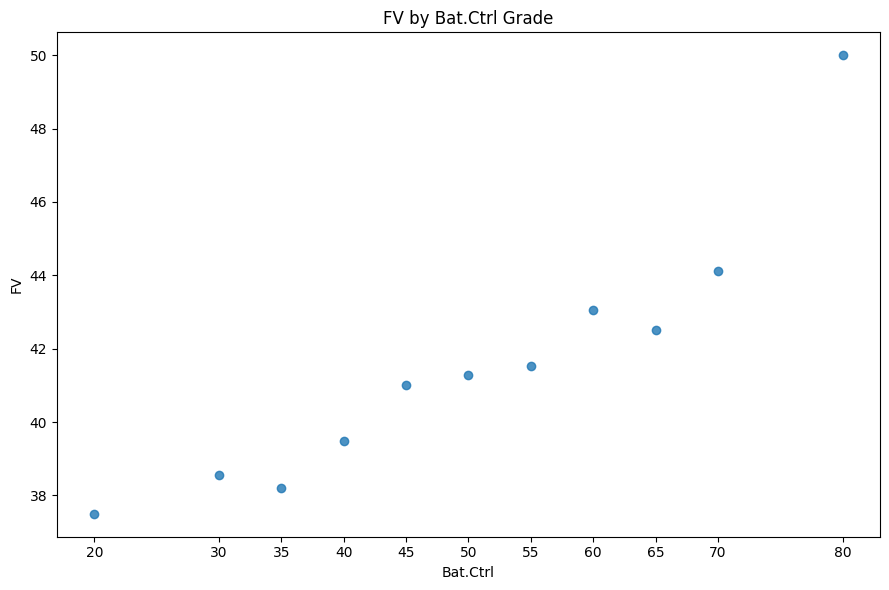

In [180]:
for grade in grade_columns:
    FV_grade = (
        clean_data.dropna(subset=[grade, "FV"])
        .groupby(grade)["FV"]
        .mean()
        .reset_index()
    )

    plt.figure(figsize=(9, 6))
    plt.scatter(
        FV_grade[grade],
        FV_grade["FV"],
        alpha=0.8
    )

    plt.title(f"FV by {grade} Grade")
    plt.xlabel(grade)
    plt.ylabel("FV")
    plt.xticks(sorted(FV_grade[grade].unique()))
    plt.tight_layout()
    plt.show()